# Landsat Data Preparation

This notebook prepares Landsat imagery for the analysis of land-cover change in Lublin in 2006, 2016 and 2026.

The workflow:
- loads and validates the study-area boundaries,
- converts the Area of Interest (AOI) to a format compatible with Google Earth Engine,
- checks Landsat scene availability for the selected summer period,
- applies sensor-specific preprocessing,
- creates seasonal median composites,
- visually inspects RGB composites,
- evaluates the number of valid observations available for each analysed year.

## Environment and project setup

The required Python libraries and reusable Earth Engine preprocessing functions are loaded. Project paths are defined relative to the repository root to avoid machine-specific absolute paths.

In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import sys
import json
import ee
import geemap

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

from gee_utils import ( preprocess_landsat5,
preprocess_landsat8, 
create_composite
)

ee.Initialize()
print("Earth Engine initialized")

Earth Engine initialized


## Study-area data

The administrative boundary of Lublin and the district boundaries are loaded from the project data directory.

The city boundary defines the common Area of Interest (AOI), while the district boundaries are retained for later district-level analyses.

In [2]:
CITY_PATH = (
    PROJECT_ROOT
    / "data"
    / "boundaries"
    / "city"
    / "lublin_city_boundary.shp"
)

DISTRICTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "boundaries"
    / "districts"
    / "dzielnice_granice.shp"
)

print("City:", CITY_PATH)
print("Districts:", DISTRICTS_PATH)

City: c:\Users\Nitro\Desktop\PROJEKTY\lublin-urban-growth\data\boundaries\city\lublin_city_boundary.shp
Districts: c:\Users\Nitro\Desktop\PROJEKTY\lublin-urban-growth\data\boundaries\districts\dzielnice_granice.shp


## Boundary validation

The city and district datasets are checked for their coordinate reference system, number of features and geometry validity.

The expected result is one city boundary and 27 valid district geometries.

In [3]:
city = gpd.read_file(CITY_PATH)
districts = gpd.read_file(DISTRICTS_PATH)

print("City CRS:", city.crs)
print("Districts CRS:", districts.crs)

print("City features:", len(city))
print("District features:", len(districts))

print("City geometry valid:", city.geometry.is_valid.all())
print("District geometries valid:", districts.geometry.is_valid.all())

City CRS: EPSG:2179
Districts CRS: EPSG:2179
City features: 1
District features: 27
City geometry valid: True
District geometries valid: True


### City area

The area of the dissolved city boundary is calculated in square kilometres as a basic consistency check.

In [4]:
city_area_km2 = city.geometry.area.sum() / 1_000_000
print(f"City area: {city_area_km2:.2f} km²")

City area: 147.48 km²


### Visual boundary check

The district boundaries are plotted together with the city outline to verify that the dissolved city boundary spatially matches the original district dataset.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

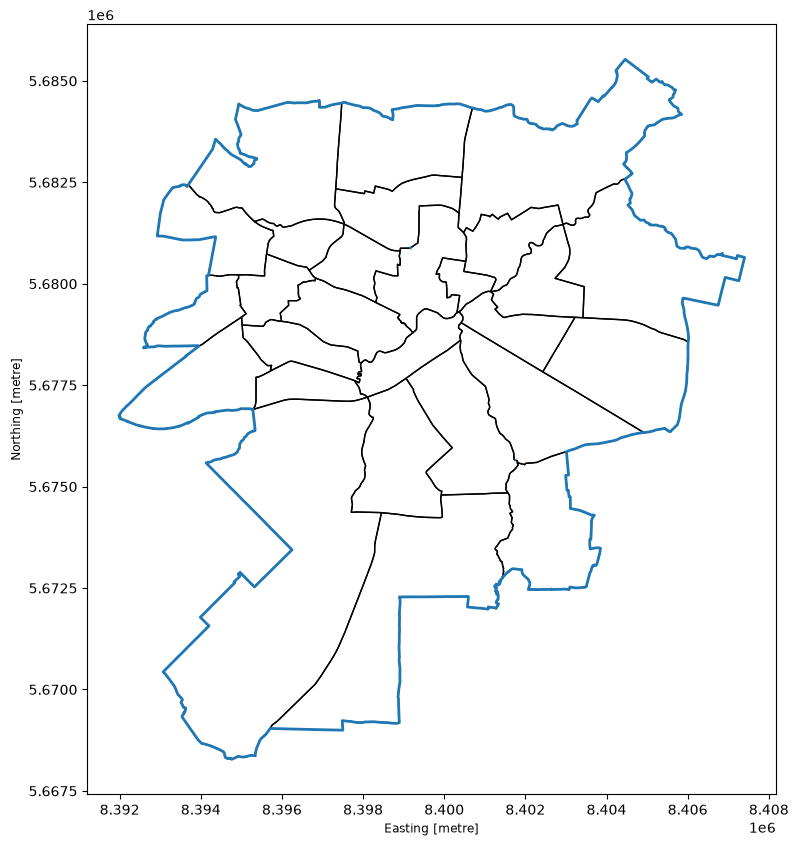

In [5]:
ax = districts.plot(
    figsize=(10, 10),
    edgecolor="black",
    facecolor="none"
)

city.boundary.plot(
    ax=ax,
    linewidth=2
)

### Area consistency check

The sum of the district areas is compared with the area of the dissolved city boundary.

Only a negligible numerical difference is expected because both datasets describe the same administrative extent.

In [6]:
districts_area_km2 = districts.geometry.area.sum() / 1_000_000
city_area_km2 = city.geometry.area.sum() / 1_000_000

print(f"Suma dzielnic: {districts_area_km2:.4f} km²")
print(f"Miasto: {city_area_km2:.4f} km²")
print(f"Różnica: {districts_area_km2 - city_area_km2:.6f} km²")

Suma dzielnic: 147.4805 km²
Miasto: 147.4804 km²
Różnica: 0.000034 km²


## Prepare the Area of Interest for Earth Engine

The local boundary datasets are stored in the Polish PL-2000 coordinate reference system. They are converted to WGS84 (EPSG:4326) before being transferred to Google Earth Engine.

In [7]:
city_wgs84 = city.to_crs(epsg=4326)
districts_wgs84 = districts.to_crs(epsg=4326)

print(city_wgs84.crs)
print(districts_wgs84.crs)

EPSG:4326
EPSG:4326


### Convert the city boundary to an Earth Engine geometry

The WGS84 city boundary is converted to GeoJSON and then to an Earth Engine geometry. This geometry defines the spatial extent used to filter and clip Landsat imagery.

In [8]:
city_geojson = json.loads(city_wgs84.to_json())

aoi = ee.Geometry(
    city_geojson["features"][0]["geometry"]
)

print(aoi.getInfo()["type"])

Polygon


### Visual AOI check

The Earth Engine Area of Interest is displayed on an interactive map to verify its position and spatial extent before satellite data are processed.

In [9]:
Map = geemap.Map()

Map.centerObject(aoi, 11)
Map.addLayer(aoi, {"color": "red"}, "Lublin AOI")

Map

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

## Landsat scene availability

A consistent summer observation window from June 1 to September 1 is used for all three analysed years.

The end date in Earth Engine is exclusive, so this interval includes all observations from June, July and August.

Landsat 5 TM is used for 2006, while Landsat 8 OLI is used for both 2016 and 2026 to maintain sensor consistency across the second analysed decade.

In [10]:
SEASON_START = "-06-01"
SEASON_END = "-09-01"  # koniec jest wyłączny, więc obejmuje cały sierpień

landsat_2006 = (
    ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
    .filterBounds(aoi)
    .filterDate("2006" + SEASON_START, "2006" + SEASON_END)
)

landsat_2016 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(aoi)
    .filterDate("2016" + SEASON_START, "2016" + SEASON_END)
)

landsat_2026 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(aoi)
    .filterDate("2026" + SEASON_START, "2026" + SEASON_END)
)

print("2006:", landsat_2006.size().getInfo())
print("2016:", landsat_2016.size().getInfo())
print("2026:", landsat_2026.size().getInfo())

2006: 15
2016: 12
2026: 14


### Scene metadata

Scene acquisition dates, cloud-cover metadata and Landsat product identifiers are collected for each analysed year.

The `CLOUD_COVER` field describes the entire Landsat scene and is used here only as a preliminary availability and quality indicator. Pixel-level cloud masking is applied separately during preprocessing.

In [11]:
def get_scene_info(collection):
    images = collection.toList(collection.size())
    result = []

    for i in range(collection.size().getInfo()):
        image = ee.Image(images.get(i))
        result.append({
            "date": ee.Date(image.get("system:time_start")).format("YYYY-MM-dd").getInfo(),
            "cloud_cover": image.get("CLOUD_COVER").getInfo(),
            "product_id": image.get("LANDSAT_PRODUCT_ID").getInfo()
        })

    return result

scene_info_2006 = get_scene_info(landsat_2006)
scene_info_2016 = get_scene_info(landsat_2016)
scene_info_2026 = get_scene_info(landsat_2026)



### Scene availability table

The retrieved scene metadata are combined into a single table to allow direct comparison between the three analysed years.

In [12]:
df_2006 = pd.DataFrame(scene_info_2006)
df_2016 = pd.DataFrame(scene_info_2016)
df_2026 = pd.DataFrame(scene_info_2026)

df_2006["year"] = 2006
df_2016["year"] = 2016
df_2026["year"] = 2026

scenes_df = pd.concat(
    [df_2006, df_2016, df_2026],
    ignore_index=True
)

scenes_df = scenes_df[
    ["year", "date", "cloud_cover", "product_id"]
].sort_values(["year", "date", "cloud_cover"])

scenes_df

,year,date,cloud_cover,product_id
9,2006,2006-06-10,69.00,LT05_L2SP_187024_20060610_20200901_02_T1
4,2006,2006-06-19,47.00,LT05_L2SP_186025_20060619_20200901_02_T1
0,2006,2006-06-19,59.00,LT05_L2SP_186024_20060619_20200901_02_T1
10,2006,2006-06-26,3.00,LT05_L2SP_187024_20060626_20200831_02_T1
5,2006,2006-07-05,11.00,LT05_L2SP_186025_20060705_20200831_02_T1
1,2006,2006-07-05,48.00,LT05_L2SP_186024_20060705_20200831_02_T1
11,2006,2006-07-12,17.00,LT05_L2SP_187024_20060712_20200831_02_T1
2,2006,2006-07-21,2.00,LT05_L2SP_186024_20060721_20200831_02_T1
6,2006,2006-07-21,38.00,LT05_L2SP_186025_20060721_20200831_02_T1
12,2006,2006-07-28,0.00,LT05_L2SP_187024_20060728_20200831_02_T1


### Scene availability summary

For each year, the number of scenes, number of unique acquisition dates and basic cloud-cover statistics are summarized.

These values provide an initial overview of data availability before cloud and shadow masking is applied.

In [13]:
summary = (
    scenes_df
    .groupby("year")
    .agg(
        scene_count=("product_id", "count"),
        unique_dates=("date", "nunique"),
        min_cloud_cover=("cloud_cover", "min"),
        median_cloud_cover=("cloud_cover", "median"),
        max_cloud_cover=("cloud_cover", "max")
    )
)

summary

,scene_count,unique_dates,min_cloud_cover,median_cloud_cover,max_cloud_cover
year,,,,,
2006,15,11,0.00,48.000,94.00
2016,12,11,0.47,65.845,100.00
2026,14,11,7.58,40.570,98.49


## Landsat preprocessing

Sensor-specific preprocessing functions are applied to all Landsat scenes.

The preprocessing workflow:
- masks invalid pixels, clouds, cloud shadows and snow using `QA_PIXEL`,
- removes radiometrically saturated pixels using `QA_RADSAT`,
- applies the Landsat Collection 2 Level-2 surface-reflectance scaling,
- renames optical bands to a common set of names.

This produces comparable predictor bands for Landsat 5 and Landsat 8.

In [14]:
processed_2006 = landsat_2006.map(preprocess_landsat5)
processed_2016 = landsat_2016.map(preprocess_landsat8)
processed_2026 = landsat_2026.map(preprocess_landsat8)

## Seasonal median composites

A median composite is created from all preprocessed summer observations for each analysed year.

Using a seasonal median reduces the influence of remaining anomalous observations and provides one representative image for each year.

In [15]:
composite_2006 = create_composite(
    "LANDSAT/LT05/C02/T1_L2",
    "2006-06-01",
    "2006-09-01",
    aoi,
    preprocess_landsat5
)

composite_2016 = create_composite(
    "LANDSAT/LC08/C02/T1_L2",
    "2016-06-01",
    "2016-09-01",
    aoi,
    preprocess_landsat8
)

composite_2026 = create_composite(
    "LANDSAT/LC08/C02/T1_L2",
    "2026-06-01",
    "2026-09-01",
    aoi,
    preprocess_landsat8
)

### Harmonized band structure

The resulting composites are checked to verify that Landsat 5 and Landsat 8 produce the same harmonized set of optical band names.

In [16]:
print("2006 bands:", composite_2006.bandNames().getInfo())
print("2016 bands:", composite_2016.bandNames().getInfo())
print("2026 bands:", composite_2026.bandNames().getInfo())

2006 bands: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
2016 bands: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
2026 bands: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']


## RGB composite inspection

True-colour RGB composites are displayed for 2006, 2016 and 2026.

This visual inspection is used to identify obvious cloud contamination, spatial artefacts or other problems before spectral indices and land-cover classification are calculated.

In [17]:
rgb_vis = {
    "bands": ["red", "green", "blue"],
    "min": 0.02,
    "max": 0.3
}

Map = geemap.Map()
Map.centerObject(aoi, 11)

Map.addLayer(composite_2006, rgb_vis, "RGB 2006")
Map.addLayer(composite_2016, rgb_vis, "RGB 2016")
Map.addLayer(composite_2026, rgb_vis, "RGB 2026")
Map.addLayer(aoi, {"color": "red"}, "Lublin AOI")

Map

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

## Valid observation count

The number of valid observations contributing to the seasonal composite is calculated for every pixel.

This provides a simple quality-control measure showing how many cloud-free and otherwise valid observations were available across the study area.

In [18]:
valid_count_2006 = processed_2006.select("red").count().clip(aoi)
valid_count_2016 = processed_2016.select("red").count().clip(aoi)
valid_count_2026 = processed_2026.select("red").count().clip(aoi)

### Spatial distribution of valid observations

The valid-observation count is displayed spatially for each year to verify that the complete study area is supported by usable Landsat observations.

In [19]:
count_vis = {
    "min": 0,
    "max": 10,
    "palette": ["red", "orange", "yellow", "lightgreen", "green"]
}

Map_count = geemap.Map()
Map_count.centerObject(aoi, 11)

Map_count.addLayer(valid_count_2006, count_vis, "Valid observations 2006")
Map_count.addLayer(valid_count_2016, count_vis, "Valid observations 2016")
Map_count.addLayer(valid_count_2026, count_vis, "Valid observations 2026")

Map_count.addLayer(aoi, {"color": "black"}, "Lublin AOI")

Map_count

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

### Valid-observation statistics

Minimum, mean and maximum valid-observation counts are calculated for each year.

The results confirm whether any parts of the study area lack valid observations and provide a compact summary of the temporal support of the seasonal composites.

In [20]:
def observation_stats(image, aoi):
    stats = image.reduceRegion(
        reducer=ee.Reducer.minMax()
            .combine(
                reducer2=ee.Reducer.mean(),
                sharedInputs=True
            ),
        geometry=aoi,
        scale=30,
        maxPixels=1e9
    )

    return stats.getInfo()


print("2006:", observation_stats(valid_count_2006, aoi))
print("2016:", observation_stats(valid_count_2016, aoi))
print("2026:", observation_stats(valid_count_2026, aoi))

2006: {'red_max': 7, 'red_mean': 3.7225336539358547, 'red_min': 1}
2016: {'red_max': 6, 'red_mean': 4.572872656863909, 'red_min': 3}
2026: {'red_max': 9, 'red_mean': 3.6787293237844123, 'red_min': 1}


## Output

The notebook produces three preprocessed summer median composites representing Lublin in 2006, 2016 and 2026.

All composites use a harmonized optical band structure:

- `blue`
- `green`
- `red`
- `nir`
- `swir1`
- `swir2`

The RGB inspection and valid-observation analysis indicate whether the composites provide sufficient spatial coverage for the subsequent spectral-index and land-cover classification workflow.

The next notebook uses these preprocessing settings to calculate NDVI and NDBI and to perform land-cover classification.